# Jacobian

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ozone import Ozone, utils

model_data_path = '/Users/namsonnguyen/repo/data/AM_Data/SON50_w_opacity/'
#freq_range = (210, 240)
my_ozone = Ozone(model_data_path)#, freq_range=freq_range)

freq_channels = my_ozone.am_model.freq_map
freq_mask = my_ozone.am_model.freq_mask

idx=5
nscale_map = my_ozone.am_model.lognscale_map
lognscale = nscale_map[idx]
print(f'Log Nscale: {lognscale}')

airmass_map = my_ozone.am_model.logairmass_map
logairmass = airmass_map[idx]
print(f'Log Airmass: {logairmass}')

am_data = np.load(f'/Users/namsonnguyen/repo/data/AM_Data/SON50_w_opacity/MaunaKea_Tb_Spectrum_{logairmass:.3f}_+{lognscale:.3f}.out')

#                            (1643.44 um_pwv)   (2658.58 um_pwv)  

2.110218730801302
Log Nscale: 0.25
Log Airmass: 0.801


In [4]:
return_array = ['model']

'model' in return_array

True

1.1052849082110792 2.7095744851194183


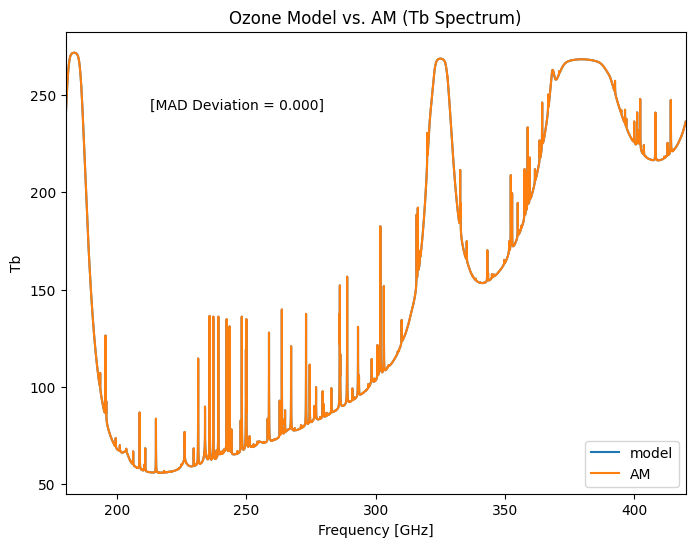

In [8]:
lognscale = 0.25
logairmass = 0.801

za = utils.airmass_to_zenith(np.exp(logairmass))
pwv = (np.exp(lognscale))*my_ozone.am_model.nominal_pwv
print(za, pwv)
eval_pwv = pwv
eval_za = za

model_Tb = my_ozone(pwv, za)[0]
am_Tb = am_data[:,4]

plt.figure(figsize=(8, 6))
deviation = ((model_Tb - am_Tb) / am_Tb) * 100
max_deviation = np.percentile(deviation, 99)
plt.figtext(0.23, 0.75, f'[MAD Deviation = {np.median(np.abs(deviation)):.3f}]')

plt.plot(
    freq_channels,
    model_Tb,
    label="model"
)
plt.plot(
    freq_channels,
    am_Tb,
    label="AM"
)

plt.legend()

plt.title(f'Ozone Model vs. AM (Tb Spectrum)')
plt.xlabel(f'Frequency [GHz]')
plt.ylabel(f'Tb')
freq_range = my_ozone.freq_range
plt.xlim(freq_range)

assert max_deviation < 1.0
assert np.median(np.abs(deviation)) < 0.1

AssertionError: 

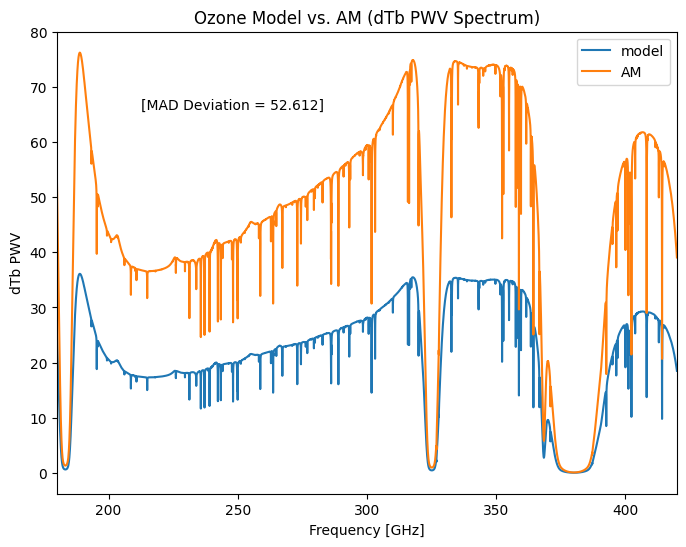

In [7]:
model_dTb_pwv = my_ozone(pwv, za)[1]
am_dTb_pwv = am_data[:,6]

plt.figure(figsize=(8, 6))
deviation = ((model_dTb_pwv - am_dTb_pwv) / am_dTb_pwv) * 100
max_deviation = np.percentile(deviation, 99)
plt.figtext(0.23, 0.75, f'[MAD Deviation = {np.median(np.abs(deviation)):.3f}]')

plt.plot(
    freq_channels,
    model_dTb_pwv,
    label="model"
)
plt.plot(
    freq_channels,
    am_dTb_pwv,
    label="AM"
)

plt.legend()

plt.title(f'Ozone Model vs. AM (dTb PWV Spectrum)')
plt.xlabel(f'Frequency [GHz]')
plt.ylabel(f'dTb PWV')
freq_range = my_ozone.freq_range
plt.xlim(freq_range)

assert max_deviation < 1.0
assert np.median(np.abs(deviation)) < 0.1

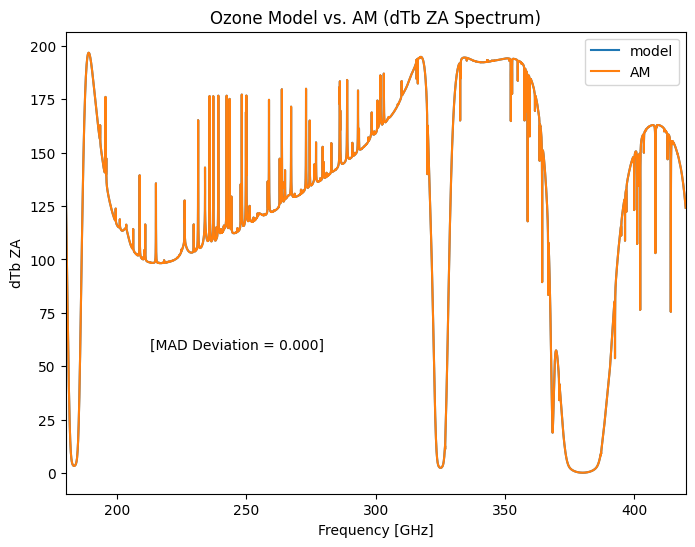

In [10]:
model_dTb_za = my_ozone(pwv, za)[2]
am_dTb_za = am_data[:,5]

plt.figure(figsize=(8, 6))
deviation = ((model_dTb_za - am_dTb_za) / am_dTb_za) * 100
max_deviation = np.percentile(deviation, 99)
plt.figtext(0.23, 0.35, f'[MAD Deviation = {np.median(np.abs(deviation)):.3f}]')

plt.plot(
    freq_channels,
    model_dTb_za,
    label="model"
)
plt.plot(
    freq_channels,
    am_dTb_za,
    label="AM"
)

plt.legend()

plt.title(f'Ozone Model vs. AM (dTb ZA Spectrum)')
plt.xlabel(f'Frequency [GHz]')
plt.ylabel(f'dTb ZA')
freq_range = my_ozone.freq_range
plt.xlim(freq_range)

assert max_deviation < 1.0
assert np.median(np.abs(deviation)) < 0.1